# 07. Forecasting
Fit a transparent damped-trend baseline to the ordered HHS-care observations. Because dates are irregular, forecast steps are future reporting observations, not daily dates.

In [6]:
# Data loading and preparation

from src.data_loader import load_raw_data
from src.preprocessing import clean_data
from src.feature_engineering import add_features

# Load raw dataset
raw = load_raw_data()

# Clean dataset
clean = clean_data(raw)

# Generate engineered features
features = add_features(clean)

# Sort reporting observations chronologically
features["date"] = pd.to_datetime(features["date"])
features = features.sort_values("date").reset_index(drop=True)

# Validate dataset
print("Features shape:", features.shape)
print("Date range:", features["date"].min(), "to", features["date"].max())
print("Missing HHS care values:", features["hhs_care"].isna().sum())

display(features.head())

Features shape: (720, 27)
Date range: 2023-01-12 00:00:00 to 2025-12-21 00:00:00
Missing HHS care values: 0


,date,cbp_intake,cbp_custody,transfers_to_hhs,hhs_care,hhs_discharges,total_system_load,hhs_net_flow,system_net_flow,hhs_discharge_offset_ratio,...,hhs_care_rolling_mean_14obs,hhs_care_rolling_std_14obs,system_load_rolling_mean_14obs,system_net_flow_sum_14obs,care_load_volatility_index,high_system_load_flag,sustained_positive_net_flow_flag,reporting_gap_days,year_month,year
0,2023-01-12,33.0,53.0,34.0,6566,436.0,6619.0,-402.0,-403.0,12.823529,...,NaN,NaN,NaN,NaN,NaN,False,False,NaN,2023-01,2023
1,2023-01-22,32.0,49.0,39.0,7122,227.0,7171.0,-188.0,-195.0,5.820513,...,NaN,NaN,NaN,NaN,NaN,False,False,10.0,2023-01,2023
2,2023-01-23,32.0,50.0,39.0,7280,181.0,7330.0,-142.0,-149.0,4.641026,...,NaN,NaN,NaN,NaN,NaN,False,False,1.0,2023-01,2023
3,2023-01-24,47.0,42.0,47.0,7433,175.0,7475.0,-128.0,-128.0,3.723404,...,NaN,NaN,NaN,NaN,NaN,False,False,1.0,2023-01,2023
4,2023-01-25,20.0,22.0,41.0,7538,180.0,7560.0,-139.0,-160.0,4.390244,...,NaN,NaN,NaN,NaN,NaN,False,False,1.0,2023-01,2023


In [7]:
from src.forecasting import forecast_hhs_care
forecast, metrics, holdout = forecast_hhs_care(features, horizon=30)
metrics

{'holdout_mae': 211.90844483838688,
 'holdout_rmse': 260.1189619245651,
 'train_observations': 576,
 'test_observations': 144,
 'forecast_horizon_reporting_observations': 30}

In [8]:
display(holdout.head())
display(forecast.head())

,actual,predicted
576,2394.0,2398.654438
577,2410.0,2402.851758
578,2437.0,2406.636854
579,2457.0,2410.050212
580,2467.0,2413.128340


,forecast_step,forecast_date_placeholder,hhs_care_forecast,lower_approx_95,upper_approx_95
0,1,2025-12-22,2486.952118,2233.872438,2740.031799
1,2,2025-12-23,2489.615450,2236.535769,2742.695130
2,3,2025-12-24,2492.018244,2238.938564,2745.097924
3,4,2025-12-25,2494.185988,2241.106308,2747.265668
4,5,2025-12-26,2496.141675,2243.061995,2749.221355


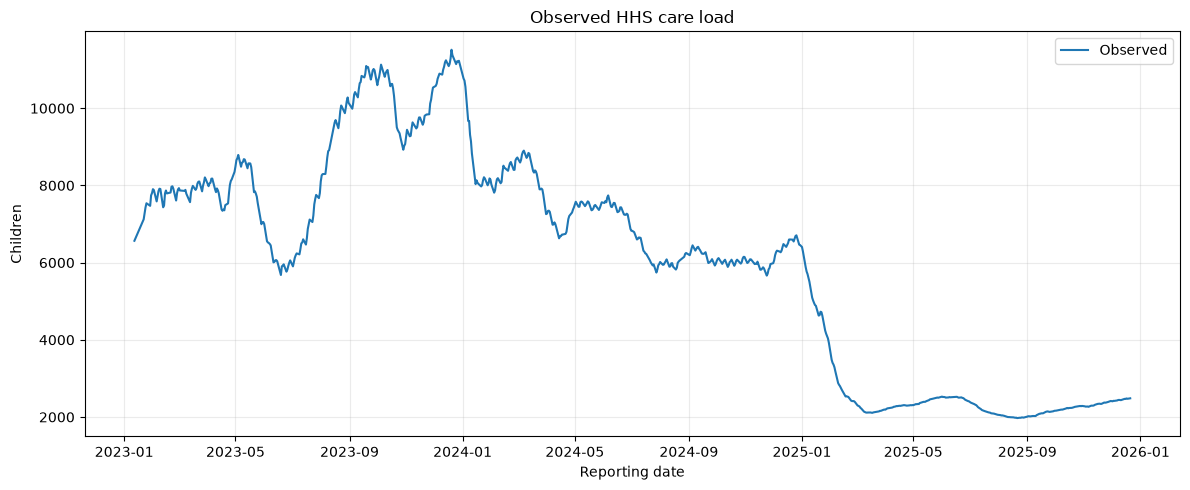

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12,5))
ax.plot(features.date, features.hhs_care, label='Observed')
ax.set(title='Observed HHS care load', xlabel='Reporting date', ylabel='Children')
ax.legend(); ax.grid(alpha=.25)
plt.tight_layout()